# Optimal Control of a Virotherapy-Chemotherapy Combination Model via Deep Reinforcement Learning
**Companion Interactive Notebook (`ODE-RL-Control.ipynb`)**

This notebook provides an executable walkthrough of the normalized `Gymnasium` ODE control environments (`ChemoViroEnv` + `NormalizedEnv`), open-loop and numerical optimal control (`L-BFGS-B`) baselines under Toxicity-Penalty Regimes A and B, live verification of the saved Stable-Baselines3 policy checkpoints in `models_normalized/`, and multi-seed summary tables and trajectory plots from `multiseed_results.json`.

* **Observation scaling:** $\tilde{o}_i = \log_{10}(1 + \max(o_i, 0)) / 8.0$
* **Action scaling:** $a^{\text{norm}} \in [-1, 1]^2 \mapsto [0, 1000] \times [0, 100]$
* **Training reward scaling:** $R_{\text{train}} = R / 10^4$ (all logged and evaluated returns reported in physical objective units $-J$)

In [1]:
import os
import sys
import json
import torch
import gymnasium
import stable_baselines3
import sb3_contrib
import scipy
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO, TD3, SAC
from sb3_contrib import TRPO

import run_multiseed_drl as R

print(f"Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | SB3: {stable_baselines3.__version__} | Gymnasium: {gymnasium.__version__} | SciPy: {scipy.__version__}")

# Verify NormalizedEnv dimensions and action/observation bounds
raw_env = R.ChemoViroEnv(ode_model="reduced", ode_params=R.ODE_PARAMS["default"], noise_config=R.NOISE_CONFIG["default"], reward_weights=(1e-2, 1e-1), use_solve_ivp=False)
norm_env = R.NormalizedEnv(raw_env, reward_scale=R.REWARD_SCALE)
obs0, _ = norm_env.reset(seed=42)
obs1, rew_scaled, done, _, _ = norm_env.step(np.array([0.0, 0.0], dtype=np.float32))  # maps [-1,1] midpoint 0.0 -> half-dose (500, 50)
print("Normalized initial obs:", np.round(obs0, 4))
print("Step 1 scaled training reward at midpoint action (500, 50):", round(float(rew_scaled), 4), "| Physical reward:", round(float(rew_scaled * R.REWARD_SCALE), 2))

Python: 3.12.10 | PyTorch: 2.10.0+cpu | SB3: 2.7.1 | Gymnasium: 1.2.3 | SciPy: 1.16.1
Normalized initial obs: [0.4998 0.247  0.3395 0.2528]
Step 1 scaled training reward at midpoint action (500, 50): -1.3665 | Physical reward: -13665.45


In [2]:
# Evaluate open-loop schedules and numerical optimum on 4D Default (Test 2, deterministic) under Regime A & Regime B
test2_cfg = R.TESTING_SCENARIOS[1]
regimes = {
    "Regime A (A1=1e-2, A2=1e-1)": (1e-2, 1e-1),
    "Regime B (A1=1e-7, A2=1e-5)": (1e-7, 1e-5),
}

for reg_label, w in regimes.items():
    x_opt = R.solve_daily_ocp(R.INITIAL_CONDITIONS["nominal_4d"], R.ODE_PARAMS["default"], False, weights=w, N=65, n_sub=40)
    schedules = [
        ("No Dosing (0, 0)", lambda t, o: (0.0, 0.0)),
        ("Constant Half-Dose (500, 50)", lambda t, o: (500.0, 50.0)),
        ("Matched Constant (600, 100)", lambda t, o: (600.0, 100.0)),
        ("Full-Dose Constant (1000, 100)", lambda t, o: (1000.0, 100.0)),
        ("Matched 2-Stage (t_sw=10 d)", lambda t, o: (1000.0, 100.0) if t < 10 else (0.0, 100.0)),
        ("Numerical Optimum (L-BFGS-B)", lambda t, o, x=x_opt: (x[t] * 1000.0, x[65 + t] * 100.0) if t < 65 else (0.0, 0.0)),
    ]
    print(f"=== {reg_label} ===")
    for name, fn in schedules:
        ev = R.eval_model_on_env(R.CallablePolicyAdapter(fn), 4, test2_cfg, w, n_episodes=1)
        print(f"  {name:32s} | Return: {ev['reward_mean']:11.1f} | Terminal (U+I): {ev['terminal_burden']:.4f} | Days: {int(ev['steps'])}")

=== Regime A (A1=1e-2, A2=1e-1) ===
  No Dosing (0, 0)                 | Return:  -1503322.9 | Terminal (U+I): 0.0730 | Days: 46
  Constant Half-Dose (500, 50)     | Return:  -1318720.6 | Terminal (U+I): 0.0660 | Days: 45
  Matched Constant (600, 100)      | Return:  -1281244.6 | Terminal (U+I): 0.0889 | Days: 44
  Full-Dose Constant (1000, 100)   | Return:  -1331054.8 | Terminal (U+I): 0.0681 | Days: 44
  Matched 2-Stage (t_sw=10 d)      | Return:  -1165143.5 | Terminal (U+I): 0.0691 | Days: 44
  Numerical Optimum (L-BFGS-B)     | Return:  -1149609.8 | Terminal (U+I): 0.0982 | Days: 44
=== Regime B (A1=1e-7, A2=1e-5) ===
  No Dosing (0, 0)                 | Return:  -1503322.9 | Terminal (U+I): 0.0730 | Days: 46
  Constant Half-Dose (500, 50)     | Return:  -1256846.7 | Terminal (U+I): 0.0660 | Days: 45
  Matched Constant (600, 100)      | Return:  -1180047.6 | Terminal (U+I): 0.0889 | Days: 44
  Full-Dose Constant (1000, 100)   | Return:  -1089059.2 | Terminal (U+I): 0.0681 | Days: 4

In [3]:
# Load saved SB3 checkpoints for Model 2 across all 5 seeds and verify bit-for-bit match with multiseed_results.json
with open("multiseed_results.json", "r") as f:
    ms_data = json.load(f)

ALGO_CLS = {"PPO": PPO, "TRPO": TRPO, "TD3": TD3, "SAC": SAC}
scen_name = "Model 2 (Reduced, Default, Noise)"
t2_name = "Test 2 (Reduced, Default, No Noise)"
stored_lookup = {(r["scenario_name"], r["algo"], r["seed"]): r for r in ms_data["rl_runs"]}

max_abs_diff = 0.0
for algo in ["PPO", "TRPO", "TD3", "SAC"]:
    live_rets = []
    for seed in R.SEEDS:
        zip_path = os.path.join("models_normalized", f"Model2_{algo}_seed{seed}.zip")
        loaded = ALGO_CLS[algo].load(zip_path, device="cpu")
        phys_pol = R.PhysicalUnitsPolicy(loaded)
        ev = R.eval_model_on_env(phys_pol, 4, R.TESTING_SCENARIOS[1], (1e-2, 1e-1), n_episodes=1, base_seed=seed * 100)
        ref_ret = stored_lookup[(scen_name, algo, seed)]["test_evals"][t2_name]["reward_mean"]
        max_abs_diff = max(max_abs_diff, abs(ev["reward_mean"] - ref_ret))
        live_rets.append(ev["reward_mean"])
    print(f"Model 2 {algo:4s} (5-seed live reload) | Test 2 Mean +/- SD: {np.mean(live_rets):11.1f} +/- {np.std(live_rets, ddof=1):7.1f}")

print(f"Maximum absolute discrepancy between reloaded .zip checkpoints and multiseed_results.json: {max_abs_diff:.2e}")

Model 2 PPO  (5-seed live reload) | Test 2 Mean +/- SD:  -1150492.0 +/-   768.4
Model 2 TRPO (5-seed live reload) | Test 2 Mean +/- SD:  -1150817.2 +/-   757.5
Model 2 TD3  (5-seed live reload) | Test 2 Mean +/- SD:  -1174968.9 +/- 13811.7
Model 2 SAC  (5-seed live reload) | Test 2 Mean +/- SD:  -1182070.9 +/-  8974.1
Maximum absolute discrepancy between reloaded .zip checkpoints and multiseed_results.json: 0.00e+00


In [4]:
# Summarize 5-seed returns across Models 1-6, Tests 1-6, and the Wide Heterogeneous Virus-Free Cohort
key_tests = [
    "Test 1 (Reduced, Default, Noise)",
    "Test 2 (Reduced, Default, No Noise)",
    "Test 4 (Full, Modified, Zero-Lysis Control)",
    "Test 5 (Reduced, Default, Virus-Free, Noise)",
    "Test 6 (Full Coupled, Virus-Free, Noise)",
]
print(f"{'Configuration':46s} | {'Test 1':>10s} | {'Test 2':>10s} | {'Test 4':>9s} | {'Test 5':>10s} | {'Test 6':>10s} | {'Wide M=10':>10s}")
print("-" * 120)
for b_name in ["No Dosing (0, 0)", "Constant Half-Dose Baseline (500, 50)", "Matched Open-Loop 2-Stage", "Log-Grid 4D DP (20^4)", "Numerical Optimum Open-Loop (L-BFGS-B)"]:
    b_runs = [b for b in ms_data["baselines"] if b["baseline_name"] == b_name]
    vals = [np.mean([b["test_evals"][t]["reward_mean"] for b in b_runs]) for t in key_tests]
    w_m = b_runs[0]["wide_cohort_reward_mean"]
    print(f"{b_name:46s} | {vals[0]:10.0f} | {vals[1]:10.0f} | {vals[2]:9.0f} | {vals[3]:10.0f} | {vals[4]:10.0f} | {w_m:10.0f}")
print("-" * 120)
for m_idx, scen in enumerate([s["name"] for s in R.TRAINING_SCENARIOS], 1):
    for algo in ["PPO", "TRPO", "TD3", "SAC"]:
        runs = [r for r in ms_data["rl_runs"] if r["scenario_name"] == scen and r["algo"] == algo]
        vals = [np.mean([r["test_evals"][t]["reward_mean"] for r in runs]) for t in key_tests]
        w_m = np.mean([r["wide_cohort_reward_mean"] for r in runs])
        label = f"Model {m_idx} - {algo}"
        print(f"{label:46s} | {vals[0]:10.0f} | {vals[1]:10.0f} | {vals[2]:9.0f} | {vals[3]:10.0f} | {vals[4]:10.0f} | {w_m:10.0f}")

Configuration                                  |     Test 1 |     Test 2 |    Test 4 |     Test 5 |     Test 6 |  Wide M=10
------------------------------------------------------------------------------------------------------------------------
No Dosing (0, 0)                               |   -1500825 |   -1503323 |    -81063 | -378125670 | -196905089 | -375763729
Constant Half-Dose Baseline (500, 50)          |   -1316683 |   -1318721 |   -107524 |   -1867024 |   -1766392 |    -514168
Matched Open-Loop 2-Stage                      |   -1163664 |   -1165143 |   -137276 |   -1465731 |   -1404068 |    -426619
Log-Grid 4D DP (20^4)                          |   -1148974 |   -1150433 |    -88596 |   -1453802 |   -1394122 |    -403692
Numerical Optimum Open-Loop (L-BFGS-B)         |   -1148140 |   -1149610 |    -80259 |   -1452846 |   -1392108 |    -410176
------------------------------------------------------------------------------------------------------------------------
Model 1 - PPO 

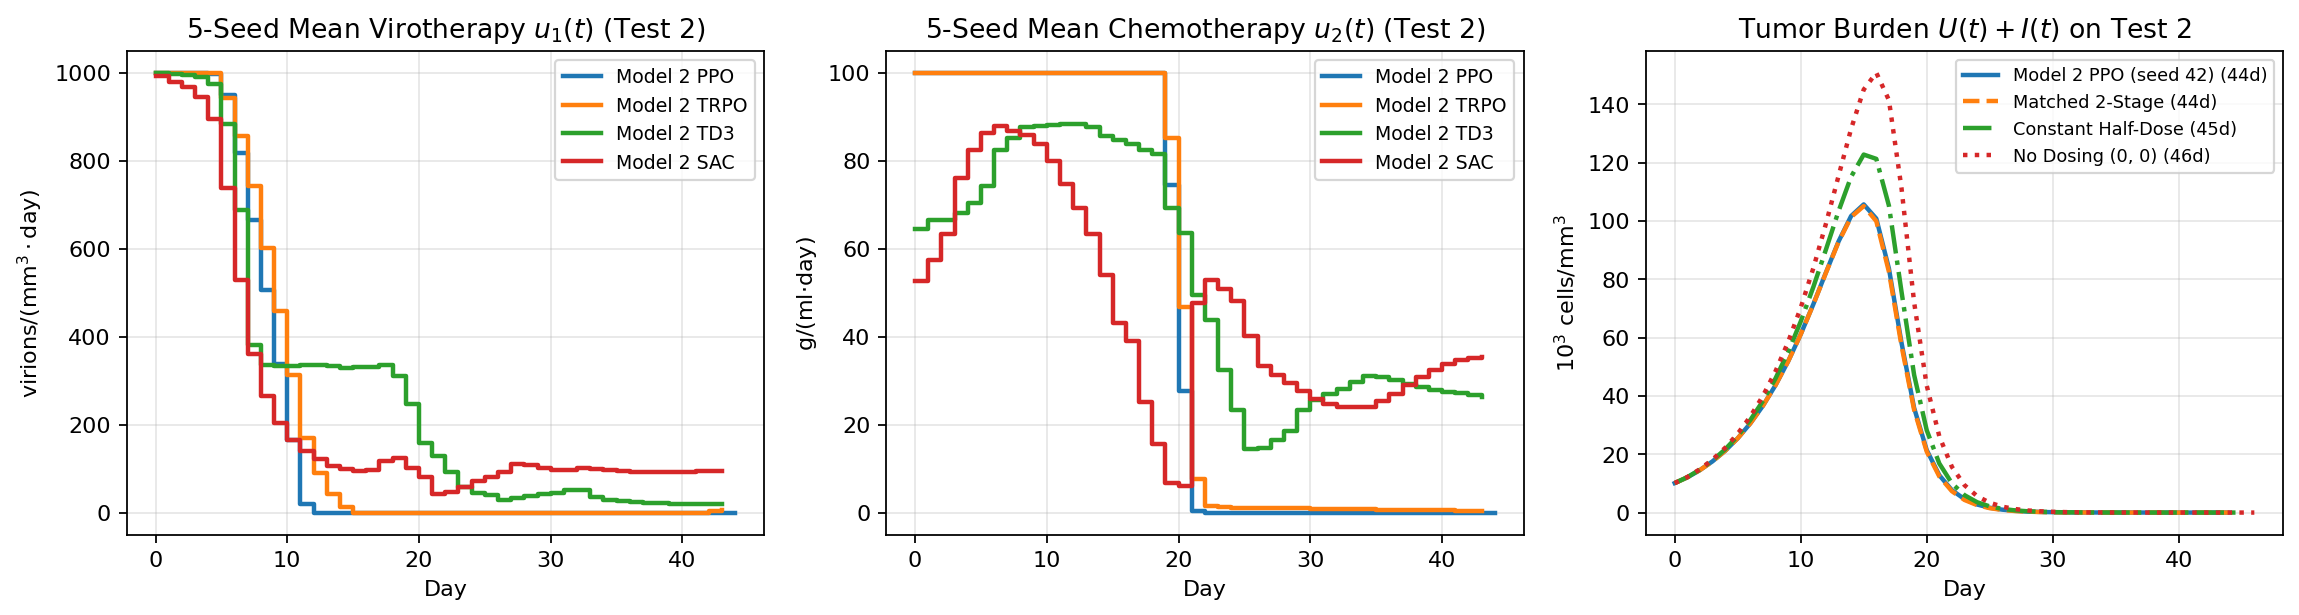

In [5]:
# Plot 5-seed Regime A dosing schedules (Model 2 PPO vs TD3 vs SAC) and tumor suppression on Test 2
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.0))
colors = {"PPO": "#1f77b4", "TRPO": "#ff7f0e", "TD3": "#2ca02c", "SAC": "#d62728"}

for algo in ["PPO", "TRPO", "TD3", "SAC"]:
    runs = sorted([r for r in ms_data["rl_runs"] if r["scenario_name"] == "Model 2 (Reduced, Default, Noise)" and r["algo"] == algo], key=lambda x: x["seed"])
    seqs = [np.array(r["test_evals"]["Test 2 (Reduced, Default, No Noise)"]["actions_sample"]) for r in runs]
    L = max(len(s) for s in seqs)
    pad = np.zeros((len(seqs), L, 2))
    for i, s in enumerate(seqs):
        pad[i, :len(s), :] = s
    axes[0].step(np.arange(L), pad[:, :, 0].mean(axis=0), where="post", lw=2.0, color=colors[algo], label=f"Model 2 {algo}")
    axes[1].step(np.arange(L), pad[:, :, 1].mean(axis=0), where="post", lw=2.0, color=colors[algo], label=f"Model 2 {algo}")

axes[0].set_title("5-Seed Mean Virotherapy $u_1(t)$ (Test 2)")
axes[0].set_xlabel("Day"); axes[0].set_ylabel(r"virions/(mm$^3\cdot$day)"); axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=8.5)
axes[1].set_title("5-Seed Mean Chemotherapy $u_2(t)$ (Test 2)")
axes[1].set_xlabel("Day"); axes[1].set_ylabel(r"g/(ml$\cdot$day)"); axes[1].grid(True, alpha=0.3); axes[1].legend(fontsize=8.5)

# Compare tumor trajectories U(t)+I(t) under reloaded Model 2 PPO (seed 42), 2-Stage, Half-Dose, and No Dosing
ppo42 = R.PhysicalUnitsPolicy(PPO.load(os.path.join("models_normalized", "Model2_PPO_seed42.zip"), device="cpu"))
for label, pol, ls in [
    ("Model 2 PPO (seed 42)", ppo42, "-"),
    ("Matched 2-Stage", R.CallablePolicyAdapter(lambda t, o: (1000.0, 100.0) if t < 10 else (0.0, 100.0)), "--"),
    ("Constant Half-Dose", R.CallablePolicyAdapter(lambda t, o: (500.0, 50.0)), "-."),
    ("No Dosing (0, 0)", R.CallablePolicyAdapter(lambda t, o: (0.0, 0.0)), ":"),
]:
    env = R.ChemoViroEnv(ode_model="reduced", ode_params=R.ODE_PARAMS["default"], noise_config=R.NOISE_CONFIG["none"], reward_weights=(1e-2, 1e-1), use_solve_ivp=True)
    obs, _ = env.reset(seed=4200)
    tum = [float(env.state[0] + env.state[1])]
    done = False
    while not done:
        a = R.predict_with_projection(pol, obs, 4, 4)
        obs, _, done, _, _ = env.step(a)
        tum.append(float(env.state[0] + env.state[1]))
    axes[2].plot(np.arange(len(tum)), np.array(tum) / 1e3, lw=2.0, linestyle=ls, label=f"{label} ({len(tum)-1}d)")

axes[2].set_title("Tumor Burden $U(t)+I(t)$ on Test 2")
axes[2].set_xlabel("Day"); axes[2].set_ylabel("$10^3$ cells/mm$^3$"); axes[2].grid(True, alpha=0.3); axes[2].legend(fontsize=8.0)
plt.tight_layout()